# SentinelAI — Phase 1: Dataset Inspection

## Dataset: CIC-IDS2017

### Objectives
1. Understand the downloaded dataset files.
2. Inspect columns, data types, and labels.
3. Analyze class distribution.
4. Identify missing values, duplicates, and infinite values.
5. Understand the dataset before preprocessing.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import os
import warnings

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
print("Current working directory:")
print(Path.cwd())

print("\nFiles and folders here:")
print(list(Path.cwd().iterdir()))

Current working directory:
c:\Users\himma\Desktop\Projects\AI project\SentinelAI\ml\notebooks

Files and folders here:
[WindowsPath('c:/Users/himma/Desktop/Projects/AI project/SentinelAI/ml/notebooks/01_dataset_overview.ipynb')]


In [3]:
DATA_DIR = Path("../data/raw/CIC-IDS2017")

print("Dataset folder exists:", DATA_DIR.exists())

Dataset folder exists: True


In [6]:
DATA_DIR = Path("../data/raw/CIC-IDS2017")

In [7]:
csv_files = list(DATA_DIR.glob("*.csv"))

print("Total CSV files:", len(csv_files))

for file in csv_files:
    print(file.name)

Total CSV files: 8
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv


In [8]:
file_info = []

for file in csv_files:
    size_mb = file.stat().st_size / (1024 * 1024)

    file_info.append({
        "File": file.name,
        "Size (MB)": round(size_mb, 2)
    })

file_info_df = pd.DataFrame(file_info)

display(file_info_df)

,File,Size (MB)
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,73.55
1,Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,73.34
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,55.62
3,Monday-WorkingHours.pcap_ISCX.csv,168.73
4,Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,79.25
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,49.61
6,Tuesday-WorkingHours.pcap_ISCX.csv,128.82
7,Wednesday-workingHours.pcap_ISCX.csv,214.74


In [9]:
dataset_summary = []

for file in csv_files:
    temp_df = pd.read_csv(file, low_memory=False)

    dataset_summary.append({
        "File": file.name,
        "Rows": temp_df.shape[0],
        "Columns": temp_df.shape[1]
    })

summary_df = pd.DataFrame(dataset_summary)

display(summary_df)

,File,Rows,Columns
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,79
1,Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,286467,79
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,79
3,Monday-WorkingHours.pcap_ISCX.csv,529918,79
4,Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,288602,79
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,170366,79
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,79
7,Wednesday-workingHours.pcap_ISCX.csv,692703,79


In [10]:
monday_file = DATA_DIR / "Monday-WorkingHours.pcap_ISCX.csv"

df = pd.read_csv(monday_file, low_memory=False)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (529918, 79)


In [26]:
display(df.sample(5))


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
356845,54626,21,1,1,6,6,6,6,6.000000,0.000000,6,6,6.000000,0.000000,571428.571429,95238.095238,21.0,0.000000e+00,21,21,0,0.000000e+00,0.000000e+00,0,0,0,0.000000e+00,0.000000e+00,0,0,0,0,0,0,20,20,47619.047619,47619.047619,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,1,9.000000,6.000000,6.000000,20,0,0,0,0,0,0,1,6,1,6,114,16068,0,20,0.000000,0.000000e+00,0,0,0.0,0.000000e+00,0,0,BENIGN
232598,443,42496640,9,12,868,5079,517,0,96.444444,168.674325,1722,0,423.250000,684.548043,139.940475,0.494157,2124832.0,9.472375e+06,42368446,0,68745,8.593125e+03,1.029816e+04,22369,3,42477080,3.861553e+06,1.277131e+07,42368446,0,0,0,0,0,192,252,0.211781,0.282375,0,1722,270.318182,534.882843,286099.655844,0,0,0,1,0,0,0,0,1,283.190476,96.444444,423.250000,192,0,0,0,0,0,0,9,868,12,5079,8192,31,8,20,128190.000000,0.000000e+00,128190,128190,42368446.0,0.000000e+00,42368446,42368446,BENIGN
109973,443,61185774,14,13,1312,4022,911,0,93.714286,243.283446,1615,2,309.384615,589.727273,87.177127,0.441279,2353299.0,4.251028e+06,9995016,17,61185774,4.706598e+06,5.135231e+06,10080638,158,61099748,5.091646e+06,5.212419e+06,10086389,221,0,0,0,0,292,264,0.228811,0.212468,0,1615,190.500000,442.799972,196071.814815,0,0,0,1,0,0,0,0,0,197.555556,93.714286,309.384615,292,0,0,0,0,0,0,14,1312,13,4022,8192,31885,13,20,165925.333333,1.966194e+05,567273,85579,9962561.0,7.932724e+04,9995016,9800635,BENIGN
41817,443,63899202,18,13,7707,1154,1277,0,428.166667,584.074658,160,0,88.769231,78.131464,138.671528,0.485139,2129973.4,8.578444e+06,44979647,4,63899202,3.758777e+06,1.127032e+07,44979647,59,62303194,5.191933e+06,1.331827e+07,45052835,4,0,0,0,0,372,284,0.281694,0.203445,0,1277,276.906250,469.087746,220043.313508,0,0,0,1,0,0,0,0,0,285.838710,428.166667,88.769231,372,0,0,0,0,0,0,18,7707,13,1154,8192,168,17,20,871513.500000,1.160905e+06,1692397,50630,30305445.5,2.075245e+07,44979647,15631244,BENIGN
447681,50846,91,1,1,0,0,0,0,0.000000,0.000000,0,0,0.000000,0.000000,0.000000,21978.021978,91.0,0.000000e+00,91,91,0,0.000000e+00,0.000000e+00,0,0,0,0.000000e+00,0.000000e+00,0,0,0,0,0,0,32,32,10989.010989,10989.010989,0,0,0.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,1,0.000000,0.000000,0.000000,32,0,0,0,0,0,0,1,0,1,0,61,270,0,32,0.000000,0.000000e+00,0,0,0.0,0.000000e+00,0,0,BENIGN


In [12]:
display(df.tail())

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
529913,443,18738,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,6.404099e+02,106.734977,18738.000000,0.000000,18738,18738,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,53.367489,53.367489,6,6,6.0,0.000000,0.0,1,0,0,0,1,0,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,0,294,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
529914,53,60797,2,2,80,156,40,40,40.0,0.0,78,78,78.0,0.0,3.881770e+03,65.792720,20265.666667,35095.968163,60791,3,3,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0,0,0,64,40,32.896360,32.896360,40,78,55.2,20.813457,433.2,0,0,0,0,0,0,0,0,1,69.0,40.0,78.0,64,0,0,0,0,0,0,2,80,2,156,-1,-1,1,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
529915,53,154,2,2,64,96,32,32,32.0,0.0,48,48,48.0,0.0,1.038961e+06,25974.025974,51.333333,50.639247,104,3,3,3.0,0.0,3,3,47,47.0,0.0,47,47,0,0,0,0,64,64,12987.012987,12987.012987,32,48,38.4,8.763561,76.8,0,0,0,0,0,0,0,0,1,48.0,32.0,48.0,64,0,0,0,0,0,0,2,64,2,96,-1,-1,1,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
529916,53,155,2,2,80,144,40,40,40.0,0.0,72,72,72.0,0.0,1.445161e+06,25806.451613,51.666667,83.428612,148,3,3,3.0,0.0,3,3,4,4.0,0.0,4,4,0,0,0,0,40,40,12903.225806,12903.225806,40,72,52.8,17.527122,307.2,0,0,0,0,0,0,0,0,1,66.0,40.0,72.0,40,0,0,0,0,0,0,2,80,2,144,-1,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
529917,52400,18,1,1,0,0,0,0,0.0,0.0,0,0,0.0,0.0,0.000000e+00,111111.111111,18.000000,0.000000,18,18,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,32,32,55555.555556,55555.555556,0,0,0.0,0.000000,0.0,0,0,0,0,1,1,0,0,1,0.0,0.0,0.0,32,0,0,0,0,0,0,1,0,1,0,357,65535,0,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [13]:
print("Total columns:", len(df.columns))

for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {repr(col)}")

Total columns: 79
1. ' Destination Port'
2. ' Flow Duration'
3. ' Total Fwd Packets'
4. ' Total Backward Packets'
5. 'Total Length of Fwd Packets'
6. ' Total Length of Bwd Packets'
7. ' Fwd Packet Length Max'
8. ' Fwd Packet Length Min'
9. ' Fwd Packet Length Mean'
10. ' Fwd Packet Length Std'
11. 'Bwd Packet Length Max'
12. ' Bwd Packet Length Min'
13. ' Bwd Packet Length Mean'
14. ' Bwd Packet Length Std'
15. 'Flow Bytes/s'
16. ' Flow Packets/s'
17. ' Flow IAT Mean'
18. ' Flow IAT Std'
19. ' Flow IAT Max'
20. ' Flow IAT Min'
21. 'Fwd IAT Total'
22. ' Fwd IAT Mean'
23. ' Fwd IAT Std'
24. ' Fwd IAT Max'
25. ' Fwd IAT Min'
26. 'Bwd IAT Total'
27. ' Bwd IAT Mean'
28. ' Bwd IAT Std'
29. ' Bwd IAT Max'
30. ' Bwd IAT Min'
31. 'Fwd PSH Flags'
32. ' Bwd PSH Flags'
33. ' Fwd URG Flags'
34. ' Bwd URG Flags'
35. ' Fwd Header Length'
36. ' Bwd Header Length'
37. 'Fwd Packets/s'
38. ' Bwd Packets/s'
39. ' Min Packet Length'
40. ' Max Packet Length'
41. ' Packet Length Mean'
42. ' Packet Length Std

In [14]:
display(
    pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str).values
    })
)

,Column,Data Type
0,Destination Port,int64
1,Flow Duration,int64
2,Total Fwd Packets,int64
3,Total Backward Packets,int64
4,Total Length of Fwd Packets,int64
5,Total Length of Bwd Packets,int64
6,Fwd Packet Length Max,int64
7,Fwd Packet Length Min,int64
8,Fwd Packet Length Mean,float64
9,Fwd Packet Length Std,float64


In [27]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count

In [28]:
label_col = "Label"

print("Label column exists:", label_col in df.columns)

Label column exists: True


In [29]:
label_counts = df[label_col].value_counts(dropna=False)

display(label_counts.to_frame(name="Number of Records"))

,Number of Records
Label,
BENIGN,529918


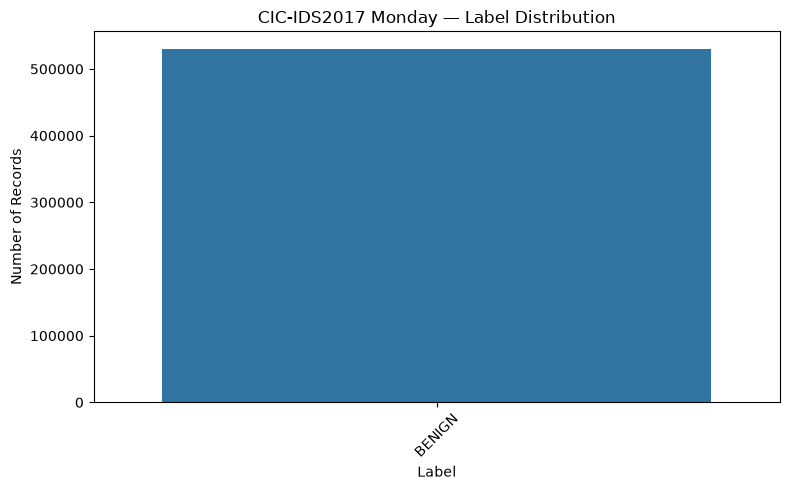

In [30]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=label_counts.index.astype(str),
    y=label_counts.values
)

plt.title("CIC-IDS2017 Monday — Label Distribution")
plt.xlabel("Label")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [31]:
label_percentages = (
    df[label_col]
    .value_counts(normalize=True, dropna=False) * 100
)

display(
    label_percentages.to_frame(name="Percentage").round(2)
)

,Percentage
Label,
BENIGN,100.0


In [32]:
for file in csv_files:
    temp_df = pd.read_csv(file, low_memory=False)
    temp_df.columns = temp_df.columns.str.strip()

    print(f"\nFile: {file.name}")
    print(temp_df["Label"].value_counts())


File: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64

File: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Label
PortScan    158930
BENIGN      127537
Name: count, dtype: int64

File: Friday-WorkingHours-Morning.pcap_ISCX.csv
Label
BENIGN    189067
Bot         1966
Name: count, dtype: int64

File: Monday-WorkingHours.pcap_ISCX.csv
Label
BENIGN    529918
Name: count, dtype: int64

File: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Label
BENIGN          288566
Infiltration        36
Name: count, dtype: int64

File: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Label
BENIGN                        168186
Web Attack � Brute Force        1507
Web Attack � XSS                 652
Web Attack � Sql Injection        21
Name: count, dtype: int64

File: Tuesday-WorkingHours.pcap_ISCX.csv
Label
BENIGN         432074
FTP-Patator      7938
SSH-Patator      5897
Name: count, dtype: int64

File: Wednesday

In [33]:
missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

missing_report = missing_report.sort_values(
    by="Missing Values",
    ascending=False
)

display(missing_report[missing_report["Missing Values"] > 0])

,Missing Values,Missing Percentage
Flow Bytes/s,64,0.012077


In [34]:
duplicate_count = df.duplicated().sum()

print("Total records:", len(df))
print("Duplicate records:", duplicate_count)
print(
    "Duplicate percentage:",
    round((duplicate_count / len(df)) * 100, 2),
    "%"
)

Total records: 529918
Duplicate records: 26935
Duplicate percentage: 5.08 %


In [35]:
numeric_df = df.select_dtypes(include=np.number)

infinite_counts = np.isinf(numeric_df).sum()

infinite_report = infinite_counts[infinite_counts > 0]

display(infinite_report)

Flow Bytes/s      373
Flow Packets/s    437
dtype: int64

In [36]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Destination Port,529918.0,1.064437e+04,2.139021e+04,0.000000e+00,53.000000,80.000000,443.000000,6.553500e+04
Flow Duration,529918.0,1.038927e+07,2.875195e+07,-1.000000e+00,176.000000,31303.000000,355744.750000,1.200000e+08
Total Fwd Packets,529918.0,1.039032e+01,8.924128e+02,1.000000e+00,2.000000,2.000000,4.000000,2.197590e+05
Total Backward Packets,529918.0,1.151710e+01,1.173319e+03,0.000000e+00,1.000000,2.000000,3.000000,2.919220e+05
Total Length of Fwd Packets,529918.0,5.324195e+02,6.228642e+03,0.000000e+00,18.000000,68.000000,187.000000,1.323378e+06
Total Length of Bwd Packets,529918.0,1.789841e+04,2.675470e+06,0.000000e+00,0.000000,144.000000,392.000000,6.554530e+08
Fwd Packet Length Max,529918.0,1.908972e+02,4.488338e+02,0.000000e+00,6.000000,40.000000,83.000000,2.336000e+04
Fwd Packet Length Min,529918.0,2.027728e+01,3.627579e+01,0.000000e+00,0.000000,6.000000,40.000000,2.293000e+03
Fwd Packet Length Mean,529918.0,5.074408e+01,9.196471e+01,0.000000e+00,6.000000,38.000000,53.000000,4.638923e+03
Fwd Packet Length Std,529918.0,5.745227e+01,1.465181e+02,0.000000e+00,0.000000,0.000000,26.162951,7.125597e+03


In [37]:
all_label_counts = []

for file in csv_files:
    temp_df = pd.read_csv(file, low_memory=False)

    temp_df.columns = temp_df.columns.str.strip()

    if "Label" not in temp_df.columns:
        print(f"Label column not found in: {file.name}")
        continue

    counts = temp_df["Label"].value_counts(dropna=False)

    for label, count in counts.items():
        all_label_counts.append({
            "File": file.name,
            "Label": label,
            "Count": count
        })

all_labels_df = pd.DataFrame(all_label_counts)

display(all_labels_df)

,File,Label,Count
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,DDoS,128027
1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,BENIGN,97718
2,Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,PortScan,158930
3,Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,BENIGN,127537
4,Friday-WorkingHours-Morning.pcap_ISCX.csv,BENIGN,189067
5,Friday-WorkingHours-Morning.pcap_ISCX.csv,Bot,1966
6,Monday-WorkingHours.pcap_ISCX.csv,BENIGN,529918
7,Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,BENIGN,288566
8,Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,Infiltration,36
9,Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,BENIGN,168186


In [38]:
total_label_counts = (
    all_labels_df
    .groupby("Label")["Count"]
    .sum()
    .sort_values(ascending=False)
)

display(total_label_counts.to_frame(name="Total Records"))

,Total Records
Label,
BENIGN,2273097
DoS Hulk,231073
PortScan,158930
DDoS,128027
DoS GoldenEye,10293
FTP-Patator,7938
SSH-Patator,5897
DoS slowloris,5796
DoS Slowhttptest,5499


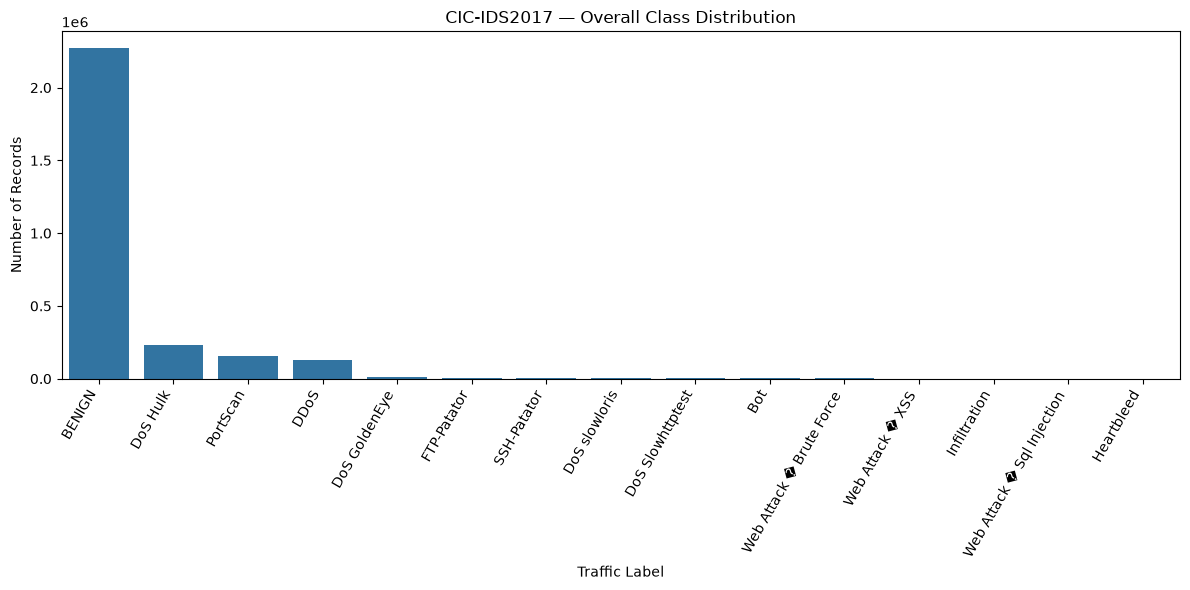

In [39]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=total_label_counts.index.astype(str),
    y=total_label_counts.values
)

plt.title("CIC-IDS2017 — Overall Class Distribution")
plt.xlabel("Traffic Label")
plt.ylabel("Number of Records")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

In [40]:
file_columns = {}

for file in csv_files:
    temp_df = pd.read_csv(file, nrows=5, low_memory=False)

    temp_df.columns = temp_df.columns.str.strip()

    file_columns[file.name] = set(temp_df.columns)

reference_file = next(iter(file_columns))

reference_columns = file_columns[reference_file]

for filename, columns in file_columns.items():
    missing = reference_columns - columns
    extra = columns - reference_columns

    print(f"\nFile: {filename}")
    print("Missing columns:", missing)
    print("Extra columns:", extra)


File: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Missing columns: set()
Extra columns: set()

File: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Missing columns: set()
Extra columns: set()

File: Friday-WorkingHours-Morning.pcap_ISCX.csv
Missing columns: set()
Extra columns: set()

File: Monday-WorkingHours.pcap_ISCX.csv
Missing columns: set()
Extra columns: set()

File: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Missing columns: set()
Extra columns: set()

File: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Missing columns: set()
Extra columns: set()

File: Tuesday-WorkingHours.pcap_ISCX.csv
Missing columns: set()
Extra columns: set()

File: Wednesday-workingHours.pcap_ISCX.csv
Missing columns: set()
Extra columns: set()


In [41]:
REPORT_DIR = Path("../data/reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

summary_df.to_csv(
    REPORT_DIR / "file_summary.csv",
    index=False
)

all_labels_df.to_csv(
    REPORT_DIR / "label_distribution_by_file.csv",
    index=False
)

print("Inspection reports saved successfully!")

Inspection reports saved successfully!


In [43]:
from pathlib import Path
import pandas as pd

# Point to the actual folder containing the CSV files
DATA_DIR = Path("../data/raw/CIC-IDS2017")

verification_rows = []
label_totals = {}

csv_files = sorted(DATA_DIR.glob("*.csv"))

if not csv_files:
    print(f"No CSV files found in: {DATA_DIR.resolve()}")
else:
    for file in csv_files:
        temp = pd.read_csv(file, low_memory=False)
        temp.columns = temp.columns.str.strip()

        if "Label" not in temp.columns:
            print(f"WARNING: Label column missing in {file.name}")
            continue

        # Clean whitespace in labels
        labels = temp["Label"].astype("string").str.strip()

        verification_rows.append({
            "File": file.name,
            "Rows": len(temp),
            "Columns": len(temp.columns),
            "Label total": labels.notna().sum()
        })

        counts = labels.value_counts(dropna=False)

        for label, count in counts.items():
            label_totals[str(label)] = (
                label_totals.get(str(label), 0) + int(count)
            )

    verification_df = pd.DataFrame(verification_rows)
    label_totals_df = pd.DataFrame(
        list(label_totals.items()),
        columns=["Label", "Count"]
    ).sort_values("Count", ascending=False)

    total_file_rows = verification_df["Rows"].sum()
    total_label_rows = label_totals_df["Count"].sum()

    display(verification_df)
    display(label_totals_df)

    print("Total rows across files:", total_file_rows)
    print("Total rows counted by labels:", total_label_rows)
    print("Do totals match?", total_file_rows == total_label_rows)


,File,Rows,Columns,Label total
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,79,225745
1,Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,286467,79,286467
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,79,191033
3,Monday-WorkingHours.pcap_ISCX.csv,529918,79,529918
4,Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,288602,79,288602
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,170366,79,170366
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,79,445909
7,Wednesday-workingHours.pcap_ISCX.csv,692703,79,692703


,Label,Count
1,BENIGN,2273097
10,DoS Hulk,231073
2,PortScan,158930
0,DDoS,128027
11,DoS GoldenEye,10293
8,FTP-Patator,7938
9,SSH-Patator,5897
12,DoS slowloris,5796
13,DoS Slowhttptest,5499
3,Bot,1966


Total rows across files: 2830743
Total rows counted by labels: 2830743
Do totals match? True


In [44]:
# Ensure column names have no leading/trailing spaces
df.columns = df.columns.str.strip()

# Examine rows with missing or infinite values in rate features
rate_columns = ["Flow Bytes/s", "Flow Packets/s"]

problem_mask = (
    df[rate_columns].isna().any(axis=1)
    | np.isinf(df[rate_columns]).any(axis=1)
)

print("Rows affected:", problem_mask.sum())

display(
    df.loc[
        problem_mask,
        ["Flow Duration", "Total Length of Fwd Packets",
         "Total Length of Bwd Packets", *rate_columns, "Label"]
    ].head(20)
)

Rows affected: 437


,Flow Duration,Total Length of Fwd Packets,Total Length of Bwd Packets,Flow Bytes/s,Flow Packets/s,Label
33,0,12,0,inf,inf,BENIGN
77,0,37,0,inf,inf,BENIGN
80,0,37,0,inf,inf,BENIGN
92,0,12,0,inf,inf,BENIGN
97,0,12,0,inf,inf,BENIGN
103,0,12,0,inf,inf,BENIGN
105,0,12,0,inf,inf,BENIGN
114,0,12,0,inf,inf,BENIGN
207,0,20,0,inf,inf,BENIGN
927,0,37,0,inf,inf,BENIGN


OverAll Inspection of all the files 

In [45]:
verification_rows = []
label_totals = {}

for file in csv_files:
    temp = pd.read_csv(file, low_memory=False)
    temp.columns = temp.columns.astype(str).str.strip()

    label_column = next(
        (col for col in temp.columns if col.lower() == "label"),
        None
    )

    if label_column is None:
        print(f"Label column not found in: {file.name}")
        continue

    labels = temp[label_column].astype("string").str.strip()

    verification_rows.append({
        "File": file.name,
        "Rows": len(temp),
        "Columns": len(temp.columns),
        "Missing labels": int(labels.isna().sum())
    })

    for label, count in labels.value_counts(dropna=False).items():
        label_name = "<MISSING>" if pd.isna(label) else str(label)
        label_totals[label_name] = (
            label_totals.get(label_name, 0) + int(count)
        )

if not verification_rows:
    print("No files were processed. Check the path and column headers.")
else:
    verification_df = pd.DataFrame(verification_rows)

    label_totals_df = pd.DataFrame(
        list(label_totals.items()),
        columns=["Label", "Count"]
    ).sort_values("Count", ascending=False)

    total_file_rows = verification_df["Rows"].sum()
    total_label_rows = label_totals_df["Count"].sum()

    display(verification_df)
    display(label_totals_df)

    print("Total rows:", total_file_rows)
    print("Total rows counted by labels:", total_label_rows)
    print("Totals match:", total_file_rows == total_label_rows)

,File,Rows,Columns,Missing labels
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,79,0
1,Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,286467,79,0
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,79,0
3,Monday-WorkingHours.pcap_ISCX.csv,529918,79,0
4,Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,288602,79,0
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,170366,79,0
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,79,0
7,Wednesday-workingHours.pcap_ISCX.csv,692703,79,0


,Label,Count
1,BENIGN,2273097
10,DoS Hulk,231073
2,PortScan,158930
0,DDoS,128027
11,DoS GoldenEye,10293
8,FTP-Patator,7938
9,SSH-Patator,5897
12,DoS slowloris,5796
13,DoS Slowhttptest,5499
3,Bot,1966


Total rows: 2830743
Total rows counted by labels: 2830743
Totals match: True


Inspect missing values, infinities, and duplicates in every file

In [46]:
quality_reports = []

for file in csv_files:
    temp = pd.read_csv(file, low_memory=False)
    temp.columns = temp.columns.astype(str).str.strip()

    numeric = temp.select_dtypes(include=np.number)

    quality_reports.append({
        "File": file.name,
        "Rows": len(temp),
        "Missing cells": int(temp.isna().sum().sum()),
        "Rows with missing values": int(temp.isna().any(axis=1).sum()),
        "Infinite cells": int(np.isinf(numeric).sum().sum()),
        "Duplicate rows": int(temp.duplicated().sum()),
        "Duplicate percentage": round(temp.duplicated().mean() * 100, 3)
    })

quality_df = pd.DataFrame(quality_reports)
display(quality_df)

,File,Rows,Missing cells,Rows with missing values,Infinite cells,Duplicate rows,Duplicate percentage
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,4,4,64,2633,1.166
1,Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,286467,15,15,727,72353,25.257
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,28,28,216,6888,3.606
3,Monday-WorkingHours.pcap_ISCX.csv,529918,64,64,810,26935,5.083
4,Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,288602,18,18,396,35630,12.346
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,170366,20,20,250,6066,3.561
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,201,201,327,24065,5.397
7,Wednesday-workingHours.pcap_ISCX.csv,692703,1008,1008,1586,81909,11.825


Then inspect which columns have missing or infinite values:

In [47]:
column_quality = []

for file in csv_files:
    temp = pd.read_csv(file, low_memory=False)
    temp.columns = temp.columns.astype(str).str.strip()

    numeric = temp.select_dtypes(include=np.number)

    for col in temp.columns:
        missing_count = int(temp[col].isna().sum())
        infinite_count = (
            int(np.isinf(numeric[col]).sum())
            if col in numeric.columns else 0
        )

        if missing_count > 0 or infinite_count > 0:
            column_quality.append({
                "File": file.name,
                "Column": col,
                "Missing": missing_count,
                "Infinite": infinite_count
            })

column_quality_df = pd.DataFrame(column_quality)
display(column_quality_df)

,File,Column,Missing,Infinite
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Flow Bytes/s,4,30
1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Flow Packets/s,0,34
2,Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,Flow Bytes/s,15,356
3,Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,Flow Packets/s,0,371
4,Friday-WorkingHours-Morning.pcap_ISCX.csv,Flow Bytes/s,28,94
5,Friday-WorkingHours-Morning.pcap_ISCX.csv,Flow Packets/s,0,122
6,Monday-WorkingHours.pcap_ISCX.csv,Flow Bytes/s,64,373
7,Monday-WorkingHours.pcap_ISCX.csv,Flow Packets/s,0,437
8,Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,Flow Bytes/s,18,189
9,Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,Flow Packets/s,0,207


only flow packets and flow bytes are missing entity

In [48]:
from collections import defaultdict

hash_to_files = defaultdict(set)
cross_file_duplicate_counts = []

for file in csv_files:
    temp = pd.read_csv(file, low_memory=False)
    temp.columns = temp.columns.astype(str).str.strip()

    # Hash each complete row to compare records across files
    row_hashes = pd.util.hash_pandas_object(
        temp,
        index=False
    )

    unique_hashes = set(row_hashes)

    cross_file_duplicate_counts.append({
        "File": file.name,
        "Rows": len(temp),
        "Unique row hashes": len(unique_hashes),
        "Repeated rows within file": int(temp.duplicated().sum())
    })

    for row_hash in unique_hashes:
        hash_to_files[row_hash].add(file.name)

cross_file_count = sum(
    1 for files in hash_to_files.values() if len(files) > 1
)

display(pd.DataFrame(cross_file_duplicate_counts))

print("Unique row hashes appearing in multiple files:", cross_file_count)

,File,Rows,Unique row hashes,Repeated rows within file
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,223112,2633
1,Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,286467,214114,72353
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,184145,6888
3,Monday-WorkingHours.pcap_ISCX.csv,529918,502983,26935
4,Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,288602,252972,35630
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,170366,164300,6066
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,421844,24065
7,Wednesday-workingHours.pcap_ISCX.csv,692703,610794,81909


Unique row hashes appearing in multiple files: 33563


In [49]:
file_columns = {}

for file in csv_files:
    headers = pd.read_csv(file, nrows=0).columns
    normalized = [str(col).strip() for col in headers]
    file_columns[file.name] = set(normalized)

reference_file = next(iter(file_columns))
reference_columns = file_columns[reference_file]

schema_comparison = []

for filename, columns in file_columns.items():
    schema_comparison.append({
        "File": filename,
        "Column count": len(columns),
        "Missing vs reference": sorted(reference_columns - columns),
        "Extra vs reference": sorted(columns - reference_columns)
    })

display(pd.DataFrame(schema_comparison))

,File,Column count,Missing vs reference,Extra vs reference
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,79,[],[]
1,Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,79,[],[]
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,79,[],[]
3,Monday-WorkingHours.pcap_ISCX.csv,79,[],[]
4,Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,79,[],[]
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,79,[],[]
6,Tuesday-WorkingHours.pcap_ISCX.csv,79,[],[]
7,Wednesday-workingHours.pcap_ISCX.csv,79,[],[]


In [50]:
all_labels = set()

for file in csv_files:
    temp = pd.read_csv(file, low_memory=False)

    temp.columns = temp.columns.astype(str).str.strip()

    label_col = next(
        (c for c in temp.columns if c.lower() == "label"),
        None
    )

    if label_col is not None:
        labels = temp[label_col].dropna().astype(str).str.strip()
        all_labels.update(labels.unique())

for label in sorted(all_labels):
    print(repr(label))

'BENIGN'
'Bot'
'DDoS'
'DoS GoldenEye'
'DoS Hulk'
'DoS Slowhttptest'
'DoS slowloris'
'FTP-Patator'
'Heartbleed'
'Infiltration'
'PortScan'
'SSH-Patator'
'Web Attack � Brute Force'
'Web Attack � Sql Injection'
'Web Attack � XSS'


In [51]:
REPORT_DIR = Path("../data/reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

quality_df.to_csv(REPORT_DIR / "data_quality_by_file.csv", index=False)
column_quality_df.to_csv(REPORT_DIR / "data_quality_by_column.csv", index=False)

print("Inspection reports saved to:", REPORT_DIR.resolve())

Inspection reports saved to: C:\Users\himma\Desktop\Projects\AI project\SentinelAI\ml\data\reports


Phase 1 — Step 4: Merge Dataset

Save in intrim folder

In [ ]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("../data/raw/CIC-IDS2017")
OUTPUT_DIR = Path("../data/interim")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

csv_files = sorted(DATA_DIR.glob("*.csv"))
dataframes = []

print(f"Merging {len(csv_files)} files...")
for file in csv_files:
    print(f"  Reading {file.name}...")
    temp = pd.read_csv(file, low_memory=False)
    temp.columns = temp.columns.astype(str).str.strip()
    temp["source_file"] = file.name
    dataframes.append(temp)

# Concatenate all files
merged_df = pd.concat(dataframes, ignore_index=True)

# Clean non-ASCII characters from attack labels (e.g. non-standard en-dashes)
if "Label" in merged_df.columns:
    merged_df["Label"] = (
        merged_df["Label"]
        .astype(str)
        .str.replace(r"[^\x00-\x7F]+", "-", regex=True)
        .str.strip()
    )

print(f"\nFinal Merged Shape: {merged_df.shape} (Expected: 2830743 rows)")

# 1. Save to Parquet (Fast & reliable, ~3 seconds)
parquet_path = OUTPUT_DIR / "cicids2017_merged_raw.parquet"
merged_df.to_parquet(parquet_path, index=False)
print("Saved Parquet to:", parquet_path.resolve())

# 2. Save to CSV (Allow it 30-40 seconds to finish without interrupting)
csv_path = OUTPUT_DIR / "cicids2017_merged_raw.csv"
merged_df.to_csv(csv_path, index=False, encoding="utf-8")
print("Saved CSV to:", csv_path.resolve())


Merging 8 files...
  Reading Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv...
  Reading Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv...
  Reading Friday-WorkingHours-Morning.pcap_ISCX.csv...
  Reading Monday-WorkingHours.pcap_ISCX.csv...
  Reading Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv...
  Reading Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv...
  Reading Tuesday-WorkingHours.pcap_ISCX.csv...
  Reading Wednesday-workingHours.pcap_ISCX.csv...

Final Merged Shape: (2830743, 80) (Expected: 2830743 rows)
Saved Parquet to: C:\Users\himma\Desktop\Projects\AI project\SentinelAI\ml\data\interim\cicids2017_merged_raw.parquet


In [11]:
from pathlib import Path
import pandas as pd

# 1. Define and ensure OUTPUT_DIR exists
OUTPUT_DIR = Path("../data/interim")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. If kernel was restarted and merged_df is not in memory, load it from CSV
if "merged_df" not in locals() and "merged_df" not in globals():
    print("Loading merged_df from CSV into memory...")
    merged_df = pd.read_csv(OUTPUT_DIR / "cicids2017_merged_raw.csv", low_memory=False)

# 3. Save as Parquet
parquet_path = OUTPUT_DIR / "cicids2017_merged_raw.parquet"
merged_df.to_parquet(parquet_path, index=False)

print(" Parquet copy saved at:", parquet_path.resolve())
print(" File size (MB):", round(parquet_path.stat().st_size / (1024 * 1024), 2))



 Parquet copy saved at: C:\Users\himma\Desktop\Projects\AI project\SentinelAI\ml\data\interim\cicids2017_merged_raw.parquet
 File size (MB): 316.01
